In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import seaborn as sns

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "..", "src"))
sys.path.insert(0, src_dir)

# Now you can import the module
import standardised_pipeline_utils
from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load
from scipy.stats import pearsonr
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram
from sklearn.utils import resample

## Pearson


In [ ]:
pearson = load('../data/full_pearson100.joblib')
pearson


,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,A2ML1-AS2,A2MP1,A3GALT2,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.207437,0.000000,0.365397,0.000000,0.000000,0.0,0.0,0.0,0.166604,...,0.000000,0.000000,0.000000,0.000000,0.0,0.070655,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.089634,0.000000,0.0,0.0,0.0,0.000000,...,-0.098537,0.000000,0.000000,0.000000,0.0,-0.074209,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,0.000000,0.086278,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,0.106925,0.000000,0.000000,0.000000,-0.147446,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.129458,-0.118349,0.098589,0.094037,-0.076360,0.0,0.0,0.0,0.094948,...,0.148686,0.104587,0.101981,0.000000,0.0,0.000000,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.104882,0.000000,-0.075800,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.148775,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,0.000000,-0.164620,0.0,0.0,0.0,0.000000,...,0.157618,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.157165,0.106069


In [3]:
transcriptomics_filtered = load('data/transcriptomics_mean_filt.joblib')
transcriptomics_filtered

,A1BG,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,AAMDC,AAMP,AAR2,...,ZUP1,ZW10,ZWILCH,ZWINT,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,1.575312,5.311430,4.531069,2.035624,5.106432,4.461398,6.166515,7.027243,4.522307,...,3.726831,4.516015,4.139142,6.986752,3.114367,4.250962,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,0.111031,5.229972,4.095924,3.035624,5.268285,4.729553,5.007196,7.341808,4.900142,...,2.327687,3.568032,3.698218,6.113742,2.659925,4.979111,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,0.933573,6.011898,5.564378,1.996389,4.595742,3.742006,3.600508,7.496974,5.429951,...,2.981853,3.930737,4.235727,7.373909,2.049631,3.471187,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,2.903038,4.842476,3.357552,2.508429,4.767125,2.853996,6.472650,6.279657,4.550285,...,3.224966,3.661065,4.584361,6.704734,1.021480,1.475085,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,3.751678,6.262847,3.874797,4.440288,5.307429,3.206331,5.111866,6.650908,4.541639,...,4.220330,4.365972,4.835924,7.356496,2.424922,3.884598,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,4.168321,5.244887,5.409391,2.121015,5.320846,3.534809,3.333424,6.992202,4.458776,...,4.277241,3.895303,4.865919,7.543882,0.028569,3.807355,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,2.163499,6.280585,4.335569,2.536053,6.667750,3.634593,5.447249,7.132474,4.223423,...,3.620586,4.280956,5.210233,6.656067,2.558268,3.754888,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,0.042644,5.667608,3.218781,0.000000,4.857981,5.175525,3.531069,6.365448,4.372256,...,4.346248,3.949535,4.143230,7.929318,1.835924,4.955127,2.107688,5.816856,3.693766,5.030777


In [ ]:
# optional: remove genes filtered out in the filtering procedure

In [4]:
# Ensure both datasets are DataFrames
pearson = pearson[transcriptomics_filtered.columns]
pearson

,A1BG,A4GALT,AAAS,AACS,AADAT,AAGAB,AAK1,AAMDC,AAMP,AAR2,...,ZUP1,ZW10,ZWILCH,ZWINT,ZXDB,ZXDC,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.000000,0.000000,0.000000,0.229227,0.000000,0.177211,0.182856,0.103783,0.144044,...,0.000000,0.000000,0.124962,0.000000,0.000000,0.000000,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,-0.160298,0.000000,0.000000,0.000000,0.000000,0.000000,-0.092836,...,0.155806,0.000000,-0.078537,-0.098537,0.000000,0.000000,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,-0.113664,0.000000,0.470513,0.000000,0.000000,0.000000,0.000000,0.120240,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,-0.121553,0.168963,0.000000,0.000000,0.349908,0.000000,0.000000,0.123288,0.000000,...,0.119060,0.000000,0.191555,0.000000,0.000000,0.000000,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.000000,0.000000,0.000000,0.184057,0.000000,0.618822,0.262843,0.136752,0.140002,...,-0.138800,0.000000,0.092193,0.148686,0.101981,0.000000,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,-0.156288,0.190009,0.000000,0.000000,0.000000,0.000000,-0.180449,0.000000,0.000000,...,0.000000,0.121233,0.000000,0.000000,0.000000,0.000000,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.096023,0.104909,0.000000,0.000000,...,0.099458,0.329151,0.000000,0.000000,0.000000,0.000000,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,-0.119140,0.155437,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.147467,0.123877,0.222471,0.157618,0.000000,0.000000,0.000000,0.000000,0.157165,0.106069


### Pearson Correlations full distribution 

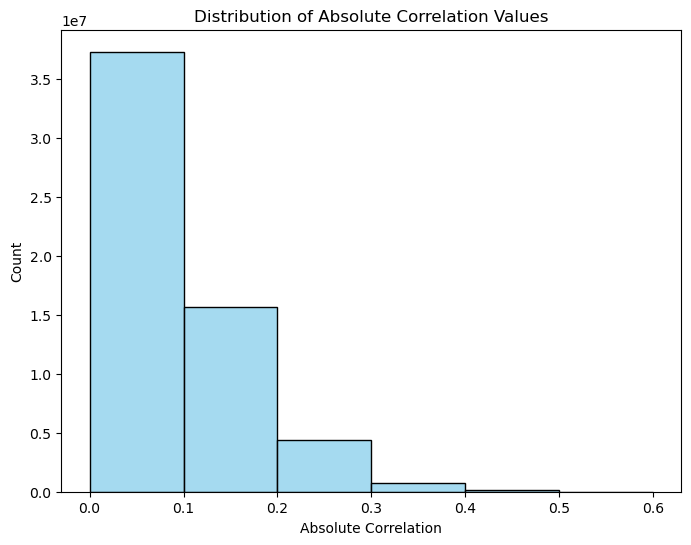

In [8]:
abs_values = pearson.abs().values.flatten()

#bins (0–0.1, 0.1–0.2, 0.2–0.3, ..., 0.9)
bins = np.arange(0, 0.7, 0.1)

plt.figure(figsize=(8, 6))
sns.histplot(abs_values, bins=bins, kde=False, color='skyblue', edgecolor='black')
plt.xlabel('Absolute Correlation')
plt.ylabel('Count')
plt.title('Distribution of Absolute Correlation Values')
plt.xticks(bins)  # Ensure the x-axis shows the bin edges
plt.show()


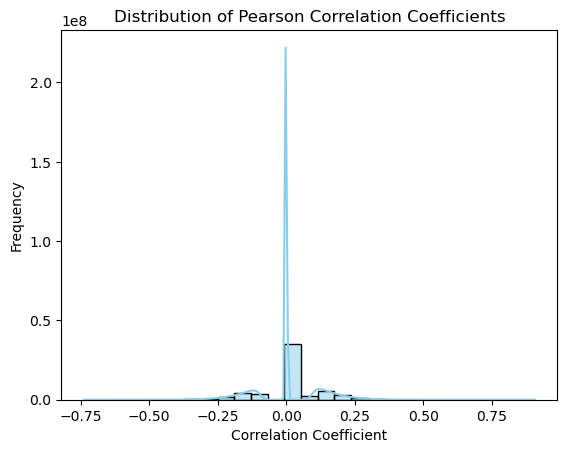

In [9]:
data = pearson.values.flatten()

# Create a histogram with a kernel density estimate (KDE) in skyblue
sns.histplot(data, color='skyblue', kde=True)

# Optional customizations
plt.title("Distribution of Pearson Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")

# Display the plot
plt.show()

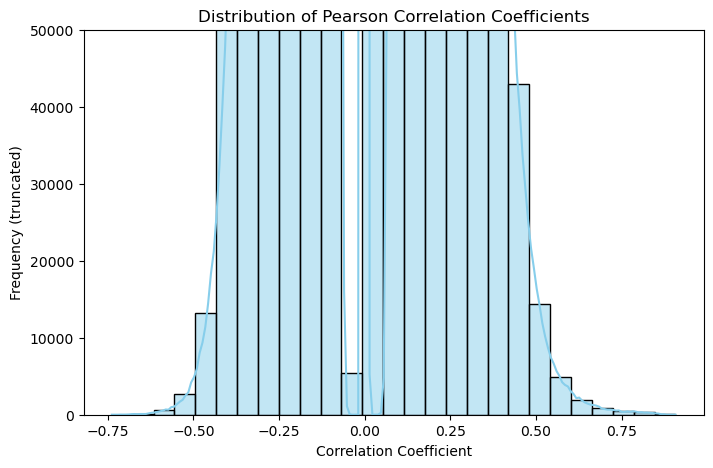

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(data, color='skyblue', kde=True)
plt.ylim(top=50000)  # Adjust for zeros
plt.title("Distribution of Pearson Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency (truncated)")
plt.show()

another approach, filter out zeros

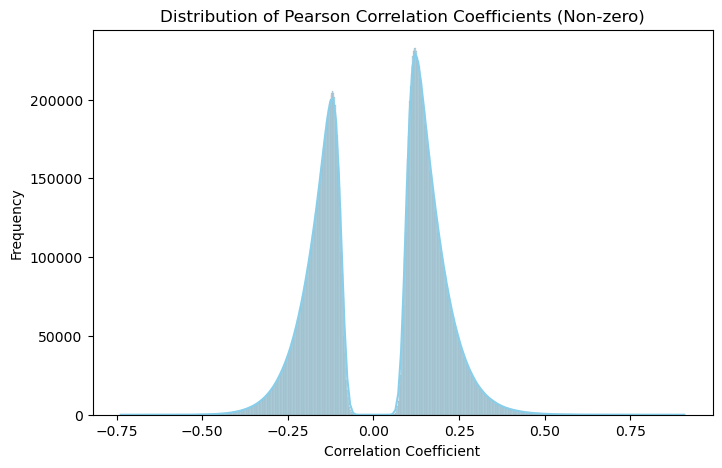

In [11]:
# Filter out exact zeros or near-zeros
non_zero_data = data[np.isclose(data, 0, atol=1e-10) == False]

plt.figure(figsize=(8, 5))
sns.histplot(non_zero_data, color='skyblue', kde=True)
plt.title("Distribution of Pearson Correlation Coefficients (Non-zero)")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")
plt.show()


### Plot protein - # correlated genes

how many zeros


In [12]:
zero_counts = (pearson == 0).sum(axis=1)

# Compute the number of genes correlated above thresholds
thresholds = [0.1, 0.2, 0.3]
thresh_counts = {t: (pearson.abs() > t).sum(axis=1) for t in thresholds}

In [13]:
# Create summary statistics
def print_summary():
    summary = pd.DataFrame({"Zero Correlations": zero_counts})
    for t in thresholds:
        summary[f"Correlated > {t}"] = thresh_counts[t]
    print(summary)

In [14]:
print_summary()

          Zero Correlations  Correlated > 0.1  Correlated > 0.2  \
proteins                                                          
A2M                    6400              4470              1254   
AAAS                   8743              2285               134   
AACS                   9154              1931                88   
AAGAB                  6139              4654               598   
AAK1                   6003              5083              1744   
...                     ...               ...               ...   
ZRANB2                 7031              4034               602   
ZW10                   9841              1260                61   
ZWILCH                 6642              4363               542   
ZYX                    7375              3686               743   
ZZZ3                   7503              3519               503   

          Correlated > 0.3  
proteins                    
A2M                    166  
AAAS                     0  
AACS        

The following histogram displays how many genes per protein have correlations above 0.1 (absolute value). It helps to understand whether most genes have weak or strong correlations with each protein.

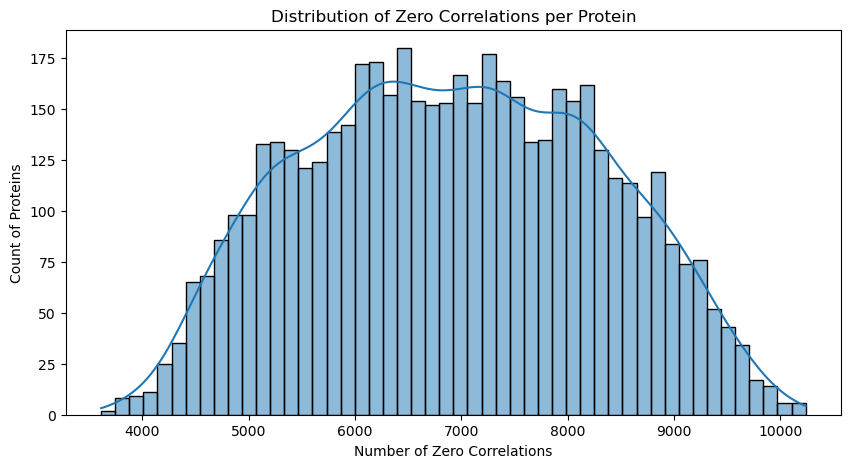

In [15]:
# Cell 1: Plot histogram of zero counts
plt.figure(figsize=(10, 5))
sns.histplot(zero_counts, bins=50, kde=True)
plt.xlabel("Number of Zero Correlations")
plt.ylabel("Count of Proteins")
plt.title("Distribution of Zero Correlations per Protein")
plt.show()

### Above 0.1 absolute correlation

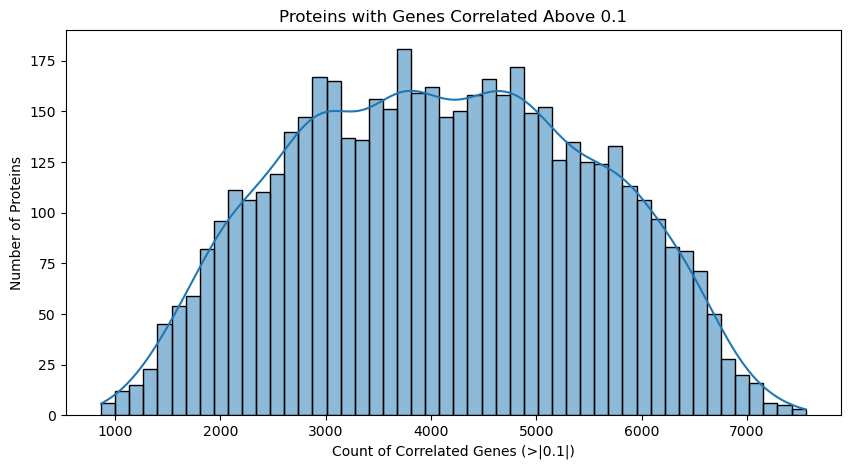

In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.1], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.1|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.1")
plt.show()

### Above 0.2 absolute correlation

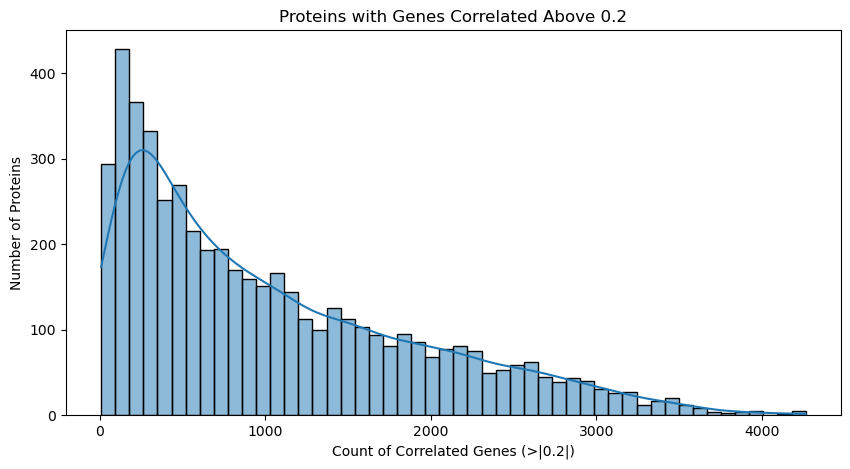

In [17]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.2], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.2|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.2")
plt.show()

### Above 0.3 absolute correlation

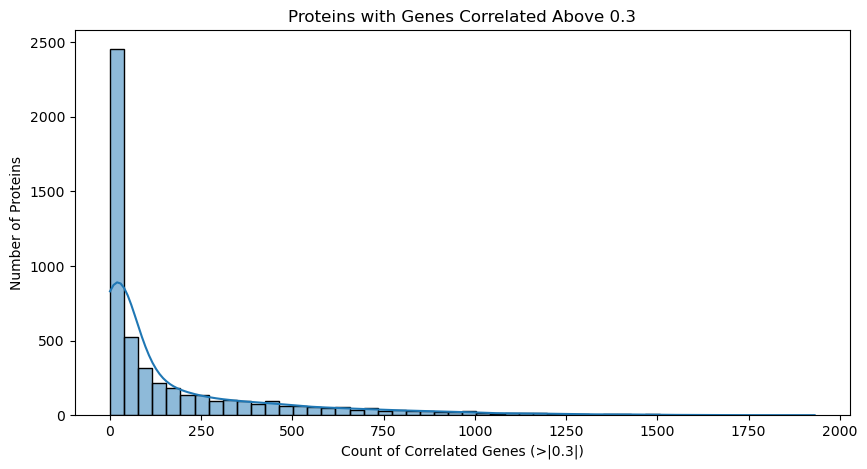

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.3], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.3|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.3")
plt.show()

### Clustermap

In [ ]:
#pip install fastcluster

In [5]:
# 1. Replace infinite values with NaN.
pearson_clean = pearson.replace([np.inf, -np.inf], np.nan)

# 2. Drop rows and columns with NaN values.
pearson_clean = pearson_clean.dropna(axis=0, how='any').dropna(axis=1, how='any')

# 3. Drop rows and columns with zero variance to avoid division-by-zero issues.
pearson_clean = pearson_clean.loc[pearson_clean.var(axis=1) != 0, :]
pearson_clean = pearson_clean.loc[:, pearson_clean.var(axis=0) != 0]

# Optional: Print shapes to ensure cleaning worked.
print("Shape after cleaning:", pearson_clean.shape)


Shape after cleaning: (5113, 11400)


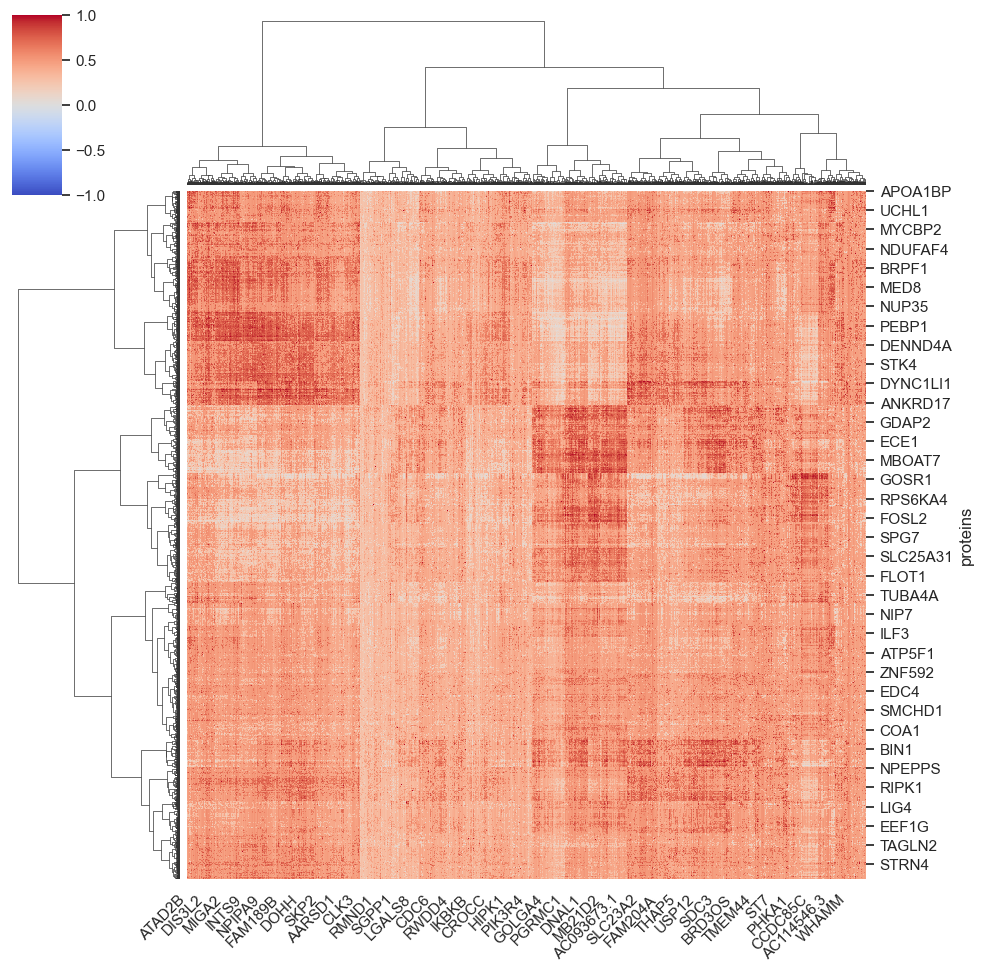

In [6]:
# Create the clustermap.
sns.set_theme(style="white")
g = sns.clustermap(
    pearson_clean,
    method="ward",         # Clustering method
    metric="euclidean",    # Distance metric
    cmap="coolwarm",           # Color map for correlation data
    center=0,              # Center the colormap at zero
    vmin=-1, vmax=1,       # Expected correlation range
    standard_scale=1,      # Standardize each row (protein)
    figsize=(10, 10)       # Figure size
)

# 5. Rotate x-axis labels for readability.
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
plt.show()


#### Consensus Clustering

In [9]:
# Parameters
num_bootstraps = 10  # Number of bootstrap samples
max_clusters = 6    # Max number of clusters to evaluate

# Number of proteins (rows) in your dataset
n_proteins = pearson_clean.shape[0]  # should be 5113

# Create consensus matrices - correct initialization
consensus_matrices = np.zeros((max_clusters - 1, n_proteins, n_proteins))

# Perform consensus clustering for k = 2 to max_clusters
for k in range(2, max_clusters + 1):
    coassociation_matrix = np.zeros((n_proteins, n_proteins))
    
    # Bootstrap sampling and clustering
    for _ in range(num_bootstraps):
        # Resample proteins (rows) only
        sampled_data = resample(pearson_clean, replace=True)
        row_linkage = sch.linkage(sampled_data, method="ward", metric="euclidean")
        clusters = sch.fcluster(row_linkage, k, criterion="maxclust")
    
        # Update coassociation matrix
        for i in range(len(clusters)):
            for j in range(len(clusters)):
                if clusters[i] == clusters[j]:
                    coassociation_matrix[i, j] += 1
    
    # Normalize to obtain consensus matrix for current k (stored at index k-2)
    consensus_matrices[k - 2] = coassociation_matrix / num_bootstraps

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

# Create a custom colormap from white to dark blue
colors = [(1, 1, 1), (0.8, 0.8, 1), (0.6, 0.6, 1), (0.4, 0.4, 1), (0, 0, 0.8)]
cmap_name = 'white_blue'
cm = LinearSegmentedColormap.from_list(cmap_name, colors, N=100)

# Function to plot a consensus matrix with ordered clusters
def plot_consensus_matrix(consensus_matrix, k, figsize=(10, 8)):
    """
    Plot a consensus matrix with hierarchical clustering to order samples.
    
    Parameters:
    consensus_matrix: The consensus matrix to plot
    k: The number of clusters this consensus matrix represents
    figsize: Size of the figure (width, height)
    """
    # Hierarchical clustering to order the matrix
    import scipy.cluster.hierarchy as sch
    
    # Calculate distances and linkage
    row_linkage = sch.linkage(consensus_matrix, method='ward')
    
    # Get cluster assignments for k clusters
    cluster_labels = sch.fcluster(row_linkage, k, criterion='maxclust')
    
    # Get indices for sorting samples by cluster
    idx_sort = np.argsort(cluster_labels)
    
    # Reorder the consensus matrix
    ordered_matrix = consensus_matrix[idx_sort, :][:, idx_sort]
    
    # Create figure
    plt.figure(figsize=figsize)
    
    # Plot heatmap
    sns.heatmap(ordered_matrix, cmap=cm, vmin=0, vmax=1, 
                cbar_kws={'label': 'Consensus Value'})
    
    # Add cluster boundaries if k > 1
    if k > 1:
        # Find boundaries between clusters in sorted matrix
        boundaries = []
        prev_label = cluster_labels[idx_sort][0]
        
        for i, label in enumerate(cluster_labels[idx_sort][1:], 1):
            if label != prev_label:
                boundaries.append(i)
                prev_label = label
        
        # Add lines to mark cluster boundaries
        for b in boundaries:
            plt.axhline(y=b, color='red', linestyle='-', linewidth=1)
            plt.axvline(x=b, color='red', linestyle='-', linewidth=1)
    
    plt.title(f'Consensus Matrix for k={k}', fontsize=16)
    plt.tight_layout()
    return plt

# Calculate the CDF for consensus values (useful for choosing k)
def plot_consensus_cdf(consensus_matrices, figsize=(10, 6)):
    """
    Plot the empirical CDF of consensus values for each k.
    
    Parameters:
    consensus_matrices: List or array of consensus matrices for each k
    figsize: Size of the figure (width, height)
    """
    plt.figure(figsize=figsize)
    
    # For each consensus matrix
    for k_idx, consensus in enumerate(consensus_matrices):
        k = k_idx + 2  # k starts at 2
        
        # Flatten the upper triangular part (excluding diagonal)
        mask = np.triu(np.ones(consensus.shape), k=1).astype(bool)
        values = consensus[mask]
        
        # Sort values for CDF
        values_sorted = np.sort(values)
        
        # Calculate empirical CDF
        cdf = np.arange(1, len(values_sorted) + 1) / len(values_sorted)
        
        # Plot CDF
        plt.plot(values_sorted, cdf, label=f'k={k}')
    
    plt.xlabel('Consensus Value')
    plt.ylabel('CDF')
    plt.title('Empirical CDF of Consensus Values', fontsize=16)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    return plt

# Function to calculate cluster stability metrics
def calculate_stability_metrics(consensus_matrices):
    """
    Calculate stability metrics for different values of k.
    
    Parameters:
    consensus_matrices: List or array of consensus matrices for each k
    
    Returns:
    DataFrame with stability metrics for each k
    """
    results = []
    
    for k_idx, consensus in enumerate(consensus_matrices):
        k = k_idx + 2  # k starts at 2
        
        # Calculate PAC (Proportion of Ambiguous Clustering)
        # PAC is defined as the proportion of sample pairs with consensus values in [0.1, 0.9]
        mask = np.triu(np.ones(consensus.shape), k=1).astype(bool)
        values = consensus[mask]
        pac = np.sum((values >= 0.1) & (values <= 0.9)) / len(values)
        
        # Calculate mean consensus value
        mean_consensus = np.mean(values)
        
        # Calculate median consensus value
        median_consensus = np.median(values)
        
        # Calculate dispersion metric (based on entropy)
        # For perfectly stable clustering, we want all values to be 0 or 1
        values_adj = np.maximum(values, 1e-10)  # Avoid log(0)
        entropy = -np.mean(values_adj * np.log2(values_adj) + 
                           (1-values_adj) * np.log2(np.maximum(1-values_adj, 1e-10)))
        
        results.append({
            'k': k,
            'PAC': pac,
            'Mean_Consensus': mean_consensus,
            'Median_Consensus': median_consensus,
            'Entropy': entropy
        })
    
    return pd.DataFrame(results)

# Example usage - visualize each consensus matrix
def visualize_all_consensus_matrices(consensus_matrices):
    """
    Visualize all consensus matrices.
    
    Parameters:
    consensus_matrices: Array of consensus matrices (k-2, n_proteins, n_proteins)
    """
    for k_idx, consensus in enumerate(consensus_matrices):
        k = k_idx + 2  # k starts at 2
        plot_consensus_matrix(consensus, k)
        plt.savefig(f'consensus_matrix_k{k}.png', dpi=300, bbox_inches='tight')
        plt.close()
    
    # Plot CDFs
    plot_consensus_cdf(consensus_matrices)
    plt.savefig('consensus_cdf.png', dpi=300, bbox_inches='tight')
    plt.close()
    
    # Calculate and plot stability metrics
    metrics = calculate_stability_metrics(consensus_matrices)
    
    # Plot PAC values (lower is better)
    plt.figure(figsize=(10, 6))
    plt.plot(metrics['k'], metrics['PAC'], 'o-', linewidth=2)
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('PAC Value')
    plt.title('Proportion of Ambiguous Clustering (lower is better)')
    plt.grid(True, alpha=0.3)
    plt.xticks(metrics['k'])
    plt.savefig('pac_values.png', dpi=300, bbox_inches='tight')
    plt.close()
    
    # Print metrics table
    print("Cluster Stability Metrics:")
    print(metrics)
    
    return metrics

# Example usage with your consensus matrices:
metrics = visualize_all_consensus_matrices(consensus_matrices)

# If memory is an issue, you can visualize one at a time:
def visualize_one_k(consensus_matrices, k):
    """Visualize consensus matrix for a specific k"""
    consensus = consensus_matrices[k-2]  # k starts at 2, so k=2 is at index 0
    plot_consensus_matrix(consensus, k)
    plt.show()

# Example for k=3:
# visualize_one_k(consensus_matrices, 3)

Cluster Stability Metrics:
   k       PAC  Mean_Consensus  Median_Consensus   Entropy
0  2  0.995219        0.585714               0.6  0.902559
1  3  0.988961        0.362656               0.4  0.867446
2  4  0.959928        0.275131               0.3  0.769085
3  5  0.931453        0.234555               0.2  0.705198
4  6  0.890457        0.198482               0.2  0.636193


In [10]:
def plot_dendrogram(linkage_matrix, threshold=None):
    """Plots the dendrogram and suggests the number of clusters based on visual gap."""
    plt.figure(figsize=(10, 5))
    dendrogram(linkage_matrix)
    if threshold:
        plt.axhline(y=threshold, color='r', linestyle='--')
    plt.xlabel("Proteins")
    plt.ylabel("Cluster Distance")
    plt.title("Dendrogram for Hierarchical Clustering")
    plt.show()


In [11]:
def elbow_method(pearson_clean, linkage_matrix, k_range=(2, 15)):
    """Computes the Elbow Method to find optimal clusters."""
    wcss = []
    for k in range(k_range[0], k_range[1]):
        labels = sch.fcluster(linkage_matrix, k, criterion='maxclust')
        cluster_var = sum(np.var(pearson_clean[labels == i], axis=0).sum() for i in np.unique(labels))
        wcss.append(cluster_var)

    # Find the "elbow" (biggest drop in variance)
    diffs = np.diff(wcss)  # First derivative
    elbow_k = k_range[0] + np.argmin(diffs)  # Best k is where WCSS drops the most

    # Plot the elbow curve
    plt.figure(figsize=(8, 4))
    plt.plot(range(k_range[0], k_range[1]), wcss, marker='o', label="WCSS")
    plt.axvline(x=elbow_k, color='r', linestyle='--', label=f"Elbow at k={elbow_k}")
    plt.xlabel("Number of Clusters")
    plt.ylabel("Within-cluster Variance (WCSS)")
    plt.title("Elbow Method for Optimal Clusters")
    plt.legend()
    plt.show()

    return elbow_k



In [12]:
def silhouette_method(pearson_clean, linkage_matrix, k_range=(2, 15)):
    """Computes the best number of clusters using the Silhouette Score."""
    best_k = k_range[0]
    best_score = -1

    for k in range(k_range[0], k_range[1]):
        labels = sch.fcluster(linkage_matrix, k, criterion='maxclust')
        score = silhouette_score(pearson_clean, labels, metric='euclidean')

        if score > best_score:
            best_score = score
            best_k = k

    return best_k

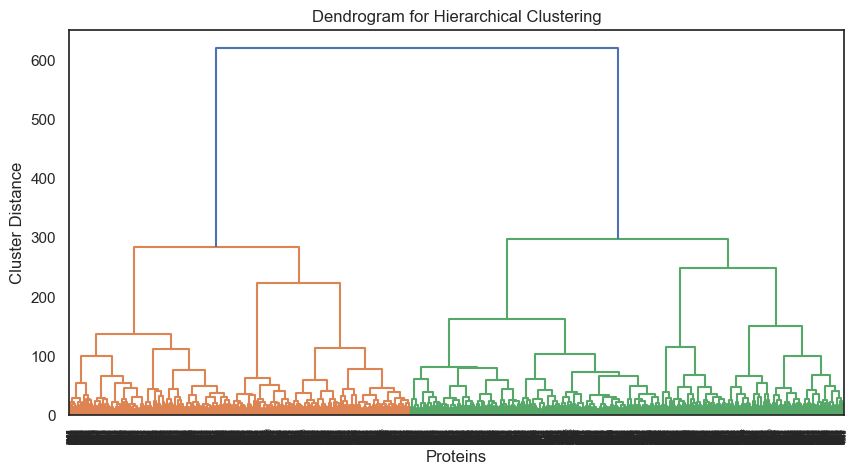

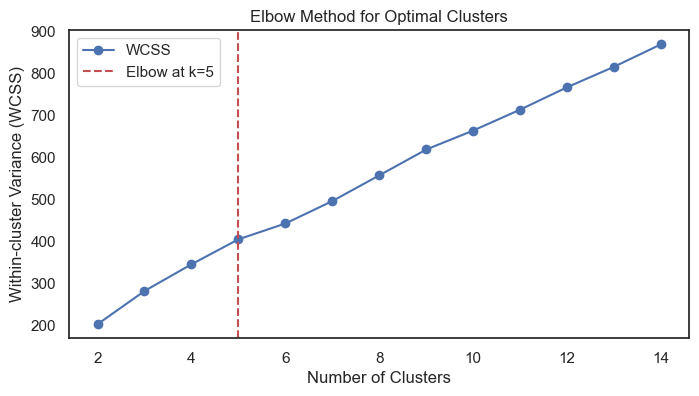

In [13]:
# Generate the hierarchical linkage matrix from the cleaned Pearson matrix
row_linkage = sch.linkage(pearson_clean, method="ward", metric="euclidean")

# 1. Dendrogram Method (Manual Inspection Required)
plot_dendrogram(row_linkage)  # Visually inspect and manually choose a number

# 2. Elbow Method
elbow_k = elbow_method(pearson_clean, row_linkage)

# 3. Silhouette Score Method
silhouette_k = silhouette_method(pearson_clean, row_linkage)


#### number of clusters according to elbow score

In [14]:
# ------------------------------
# Extracting Cluster Assignments
# ------------------------------

# The row dendrogram linkage is stored in g.dendrogram_row.linkage.
row_linkage = g.dendrogram_row.linkage

# Choose a criterion for forming flat clusters. Here we use a maximum of 4 clusters.
# You can change max_clusters or use a distance threshold with criterion='distance'
max_clusters = elbow_k
cluster_labels = fcluster(row_linkage, max_clusters, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_elbow.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters_elbow.csv'.")




Protein Clusters:
     Protein  Cluster
0        A2M        5
1       AAAS        4
2       AACS        4
3      AAGAB        5
4       AAK1        5
...      ...      ...
5108  ZRANB2        1
5109    ZW10        4
5110  ZWILCH        5
5111     ZYX        5
5112    ZZZ3        1

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters_elbow.csv'.


#### number of clusters according to silhouette score

In [26]:
max_clusters = silhouette_k
cluster_labels = fcluster(row_linkage, max_clusters, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_sil.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters.csv'.")


Protein Clusters:
     Protein  Cluster
0        A2M        2
1       AAAS        2
2       AACS        2
3      AAGAB        2
4       AAK1        2
...      ...      ...
5108  ZRANB2        1
5109    ZW10        2
5110  ZWILCH        2
5111     ZYX        2
5112    ZZZ3        1

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters.csv'.


In [14]:
optimal_k = 2

# Assign each protein to a cluster
clusters = sch.fcluster(row_linkage, optimal_k, criterion="maxclust")

# Convert to DataFrame
cluster_df = pd.DataFrame({"Protein": pearson_clean.index, "Cluster": clusters})

# Count how many proteins per cluster
cluster_sizes = cluster_df["Cluster"].value_counts().sort_index()

print(cluster_sizes)

Cluster
1    2055
2    3058
Name: count, dtype: int64


Measures cluster compactness, lower is better, with 5 clusters was 990

In [28]:
wcss = sum(np.var(pearson_clean[clusters == i], axis=0).sum() for i in np.unique(clusters))
print("Within-Cluster Variance:", wcss)


Within-Cluster Variance: 200.95594024658203


Checks how well clusters are separated closer to 1.0 means clear separation, with 5 clusters was 0.06

In [29]:
sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')
print("Silhouette Score:", sil_score)

Silhouette Score: 0.20953055


Try with different number of clusters to se the best

In [ ]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform

# Function to compute Dunn Index
def dunn_index(data, labels):
    distances = squareform(pdist(data, metric="euclidean"))
    unique_clusters = np.unique(labels)
    
    intercluster_distances = np.min([
        np.min(distances[labels == i][:, labels == j]) 
        for i in unique_clusters for j in unique_clusters if i != j
    ])
    
    intracluster_distances = np.max([
        np.max(distances[labels == i][:, labels == i]) 
        for i in unique_clusters
    ])
    
    return intercluster_distances / intracluster_distances

# Define range of cluster sizes
k_range = range(2, 11)

# Store results
results = []
wcss_values = []  # For the elbow method

for k in k_range:
    # Assign each protein to a cluster
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")

    # Convert to DataFrame
    cluster_df = pd.DataFrame({"Protein": pearson_clean.index, "Cluster": clusters})

    # Count proteins per cluster
    cluster_sizes = cluster_df["Cluster"].value_counts().sort_index()

    # Compute Within-Cluster Variance (WCSS)
    wcss = sum(np.var(pearson_clean[clusters == i], axis=0).sum() for i in np.unique(clusters))
    wcss_values.append(wcss)  # Store WCSS for elbow method

    # Compute Silhouette Score
    sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')

    # Compute Dunn Index
    dunn = dunn_index(pearson_clean.values, clusters)

    # Compute Calinski-Harabasz Index
    calinski_harabasz = calinski_harabasz_score(pearson_clean, clusters)

    # Compute Davies-Bouldin Index
    davies_bouldin = davies_bouldin_score(pearson_clean, clusters)

    # Store results
    results.append((k, cluster_sizes.to_dict(), wcss, sil_score, dunn, calinski_harabasz, davies_bouldin))

# Print results
for k, sizes, wcss, sil_score, dunn, calinski_harabasz, davies_bouldin in results:
    print(f"\nClusters: {k}")
    print(f"Cluster Sizes: {sizes}")
    print(f"Within-Cluster Variance (WCSS): {wcss:.4f}")
    print(f"Silhouette Score: {sil_score:.4f}")
    print(f"Dunn Index: {dunn:.4f}")
    print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")
    print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")


In [31]:
# Define range of cluster sizes
k_range = range(2, 11)

# Store results
results = []

for k in k_range:
    # Assign each protein to a cluster
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")

    # Convert to DataFrame
    cluster_df = pd.DataFrame({"Protein": pearson_clean.index, "Cluster": clusters})

    # Count proteins per cluster
    cluster_sizes = cluster_df["Cluster"].value_counts().sort_index()

    # Compute Within-Cluster Variance (WCSS)
    wcss = sum(np.var(pearson_clean[clusters == i], axis=0).sum() for i in np.unique(clusters))

    # Compute Silhouette Score
    sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')

    # Store results
    results.append((k, cluster_sizes.to_dict(), wcss, sil_score))

# Print results
for k, sizes, wcss, sil_score in results:
    print(f"\nClusters: {k}")
    print(f"Cluster Sizes: {sizes}")
    print(f"Within-Cluster Variance (WCSS): {wcss:.4f}")
    print(f"Silhouette Score: {sil_score:.4f}")



Clusters: 2
Cluster Sizes: {1: 1594, 2: 3519}
Within-Cluster Variance (WCSS): 200.9559
Silhouette Score: 0.2095

Clusters: 3
Cluster Sizes: {1: 1594, 2: 1313, 3: 2206}
Within-Cluster Variance (WCSS): 273.4916
Silhouette Score: 0.1367

Clusters: 4
Cluster Sizes: {1: 1594, 2: 1313, 3: 1172, 4: 1034}
Within-Cluster Variance (WCSS): 332.1191
Silhouette Score: 0.0997

Clusters: 5
Cluster Sizes: {1: 900, 2: 694, 3: 1313, 4: 1172, 5: 1034}
Within-Cluster Variance (WCSS): 387.8744
Silhouette Score: 0.0936

Clusters: 6
Cluster Sizes: {1: 900, 2: 694, 3: 503, 4: 810, 5: 1172, 6: 1034}
Within-Cluster Variance (WCSS): 451.5920
Silhouette Score: 0.0916

Clusters: 7
Cluster Sizes: {1: 900, 2: 694, 3: 503, 4: 810, 5: 1172, 6: 203, 7: 831}
Within-Cluster Variance (WCSS): 513.7755
Silhouette Score: 0.0834

Clusters: 8
Cluster Sizes: {1: 900, 2: 214, 3: 480, 4: 503, 5: 810, 6: 1172, 7: 203, 8: 831}
Within-Cluster Variance (WCSS): 552.7034
Silhouette Score: 0.0695

Clusters: 9
Cluster Sizes: {1: 900, 2:

In [32]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Assume 'clusters' is your clustering result and 'pearson_clean' is your correlation matrix (DataFrame)
clusters = sch.fcluster(row_linkage, 2, criterion="maxclust")
unique_clusters = np.unique(clusters)

cluster_stats = []

for cl in unique_clusters:
    # Get indices of proteins in the cluster
    cluster_indices = np.where(clusters == cl)[0]
    proteins = pearson_clean.index[cluster_indices]
    cluster_data = pearson_clean.iloc[cluster_indices, :]
    
    # Basic statistics
    size = len(proteins)
    centroid = cluster_data.mean(axis=0)
    intra_corr = cluster_data.values.flatten()  # all correlations within the cluster (can be filtered further)
    within_variance = cluster_data.var().sum()
    
    # Optionally, compute network-based or centrality measures here if needed
    
    cluster_stats.append({
        "Cluster": cl,
        "Size": size,
        "Centroid_Mean": centroid.mean(),  # overall average for centroid profile
        "Within_Variance": within_variance,
        "Intra_Cluster_Correlation_Mean": np.nanmean(intra_corr)
    })

# Convert to DataFrame for easier viewing
cluster_stats_df = pd.DataFrame(cluster_stats)
print(cluster_stats_df)

# Global clustering metrics (computed on all data with provided labels)
sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')
calinski_harabasz = calinski_harabasz_score(pearson_clean, clusters)
davies_bouldin = davies_bouldin_score(pearson_clean, clusters)

print(f"Global Silhouette Score: {sil_score:.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")



   Cluster  Size  Centroid_Mean  Within_Variance  \
0        1  1594       0.013972        89.682014   
1        2  3519       0.002941       111.361832   

   Intra_Cluster_Correlation_Mean  
0                        0.013972  
1                        0.002941  
Global Silhouette Score: 0.2095
Calinski-Harabasz Index: 1684.6281
Davies-Bouldin Index: 1.5404


#### PCA

Principal Component 1 (PC1):
This component captures the largest amount of variance in the data. In the context of protein correlations, PC1 can be thought of as the primary axis along which the overall correlation patterns differ the most among proteins. Proteins with similar values on PC1 share a similar overall correlation structure.

Principal Component 2 (PC2):
This component captures the second largest amount of variance, orthogonal to PC1. PC2 highlights additional variation not explained by the first component. It can reveal subtler differences between protein correlation patterns that might not be evident from PC1 alone.

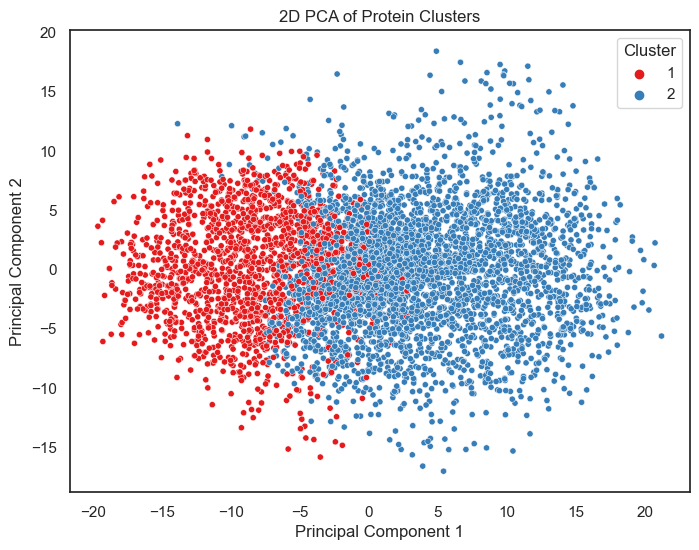

In [21]:
from sklearn.decomposition import PCA

# Compute PCA on the cleaned data, reducing to 2 dimensions
clusters = sch.fcluster(row_linkage, 2 , criterion="maxclust")
pca = PCA(n_components=2)
pca_result = pca.fit_transform(pearson_clean.values)

# Create a DataFrame for the PCA results
pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=pearson_clean.index)
pca_df["Cluster"] = clusters  # Add the cluster assignments

# Plot the clusters in 2D using a scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="Set1", s=20)
plt.title("2D PCA of Protein Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()


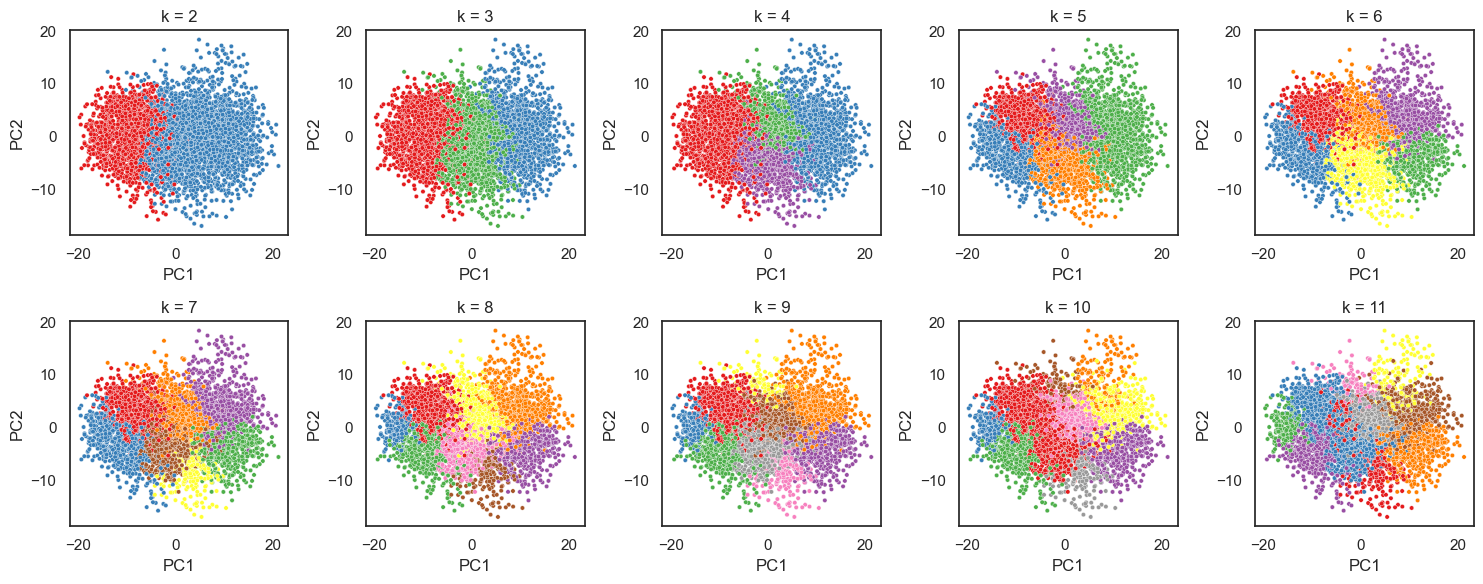

In [22]:
# Create a 2x5 grid for plots with a reduced overall figure size
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()  # flatten to easily iterate over

# Loop over cluster numbers from 2 to 10
for i, k in enumerate(range(2, 12)):
    # Compute clusters using hierarchical clustering
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")
    
    # Perform PCA on the cleaned data
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(pearson_clean.values)
    
    # Create DataFrame for PCA results with cluster assignments
    pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=pearson_clean.index)
    pca_df["Cluster"] = clusters
    
    # Plot on the corresponding axis
    ax = axes[i]
    sns.scatterplot(
        data=pca_df, 
        x="PC1", 
        y="PC2", 
        hue="Cluster", 
        palette="Set1", 
        s=10, 
        ax=ax,
        legend=False  # Disable legend for individual subplots
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

save 3 clusters

In [35]:
cluster_labels = fcluster(row_linkage, 3, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_3.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters_3.csv'.")


Protein Clusters:
     Protein  Cluster
0        A2M        3
1       AAAS        3
2       AACS        3
3      AAGAB        3
4       AAK1        3
...      ...      ...
5108  ZRANB2        1
5109    ZW10        3
5110  ZWILCH        3
5111     ZYX        3
5112    ZZZ3        1

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters_3.csv'.


save 4 clusters

In [36]:

cluster_labels = fcluster(row_linkage, 4, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_4.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters_4.csv'.")


Protein Clusters:
     Protein  Cluster
0        A2M        4
1       AAAS        3
2       AACS        3
3      AAGAB        4
4       AAK1        4
...      ...      ...
5108  ZRANB2        1
5109    ZW10        3
5110  ZWILCH        4
5111     ZYX        4
5112    ZZZ3        1

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters_4.csv'.


#### Statistical analysis of clusters

In [37]:

# Set a threshold for average gene correlation (example threshold: 0.5)
threshold = 0.1

# Create a copy of your data and add the cluster labels
data = pearson_clean.copy()
data["Cluster"] = clusters  # clusters should align with the rows of pearson_clean

# Dictionary to store summary statistics for each cluster
cluster_stats = {}

# Loop over each cluster
for cluster_label, group in data.groupby("Cluster"):
    # Remove the cluster column so that only gene correlation values remain
    group_data = group.drop(columns=["Cluster"])
    
    # Compute gene-wise statistics for the proteins in this cluster
    gene_means = group_data.mean(axis=0)
    gene_vars = group_data.var(axis=0)
    gene_min = group_data.min(axis=0)
    gene_max = group_data.max(axis=0)
    
    # Aggregate these gene-level stats to get cluster-level summary measures.
    # For example, we compute the average of the gene means, standard deviation, etc.
    cluster_summary = {
        "mean_of_gene_means": gene_means.mean(),
        "std_of_gene_means": gene_means.std(),
        "mean_of_gene_vars": gene_vars.mean(),
        "std_of_gene_vars": gene_vars.std(),
        "average_min": gene_min.mean(),
        "average_max": gene_max.mean(),
        "num_genes_above_threshold": (gene_means > threshold).sum(),
        "total_genes": len(gene_means)
    }
    
    cluster_stats[cluster_label] = cluster_summary

# Convert the dictionary to a DataFrame for easier viewing
stats_df = pd.DataFrame(cluster_stats).T
stats_df.index.name = "Cluster"
print(stats_df)


         mean_of_gene_means  std_of_gene_means  mean_of_gene_vars  \
Cluster                                                             
1                  0.013421           0.047284           0.004886   
2                 -0.001991           0.082678           0.006126   
3                  0.020268           0.138690           0.003979   
4                  0.033615           0.093369           0.005713   
5                  0.018645           0.111145           0.007056   
6                 -0.019915           0.109055           0.006637   
7                 -0.017161           0.094614           0.006557   
8                 -0.033698           0.064253           0.006068   
9                 -0.002680           0.026464           0.004970   
10                 0.038837           0.084150           0.006473   
11                 0.018605           0.036886           0.005799   

         std_of_gene_vars  average_min  average_max  \
Cluster                                        

3 clusters

In [15]:
clusters = sch.fcluster(row_linkage, 2, criterion="maxclust")


In [39]:
threshold = 0.1

# Create a copy of your data and add the cluster labels
data = pearson_clean.copy()
data["Cluster"] = clusters  # clusters should align with the rows of pearson_clean

# Dictionary to store summary statistics for each cluster
cluster_stats = {}

# Loop over each cluster
for cluster_label, group in data.groupby("Cluster"):
    # Remove the cluster column so that only gene correlation values remain
    group_data = group.drop(columns=["Cluster"])
    
    # Compute gene-wise statistics for the proteins in this cluster
    gene_means = group_data.mean(axis=0)
    gene_vars = group_data.var(axis=0)
    gene_min = group_data.min(axis=0)
    gene_max = group_data.max(axis=0)
    
    # Aggregate these gene-level stats to get cluster-level summary measures.
    # For example, we compute the average of the gene means, standard deviation, etc.
    cluster_summary = {
        "mean_of_gene_means": gene_means.mean(),
        "std_of_gene_means": gene_means.std(),
        "mean_of_gene_vars": gene_vars.mean(),
        "std_of_gene_vars": gene_vars.std(),
        "average_min": gene_min.mean(),
        "average_max": gene_max.mean(),
        "num_genes_above_threshold": (gene_means > threshold).sum(),
        "total_genes": len(gene_means)
    }
    
    cluster_stats[cluster_label] = cluster_summary

# Convert the dictionary to a DataFrame for easier viewing
stats_df = pd.DataFrame(cluster_stats).T
stats_df.index.name = "Cluster"
print(stats_df)


         mean_of_gene_means  std_of_gene_means  mean_of_gene_vars  \
Cluster                                                             
1                  0.013972           0.079247           0.007867   
2                 -0.003842           0.094523           0.008812   
3                  0.006979           0.015621           0.007327   

         std_of_gene_vars  average_min  average_max  \
Cluster                                               
1                0.004119    -0.247571     0.326307   
2                0.004971    -0.275802     0.307853   
3                0.004174    -0.295689     0.361988   

         num_genes_above_threshold  total_genes  
Cluster                                          
1                           1573.0      11400.0  
2                           1628.0      11400.0  
3                              0.0      11400.0  


## Other analyses, not ran

In [17]:
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import pairwise_distances
import networkx as nx

In [16]:
clusters = sch.fcluster(row_linkage, 2, criterion="maxclust")

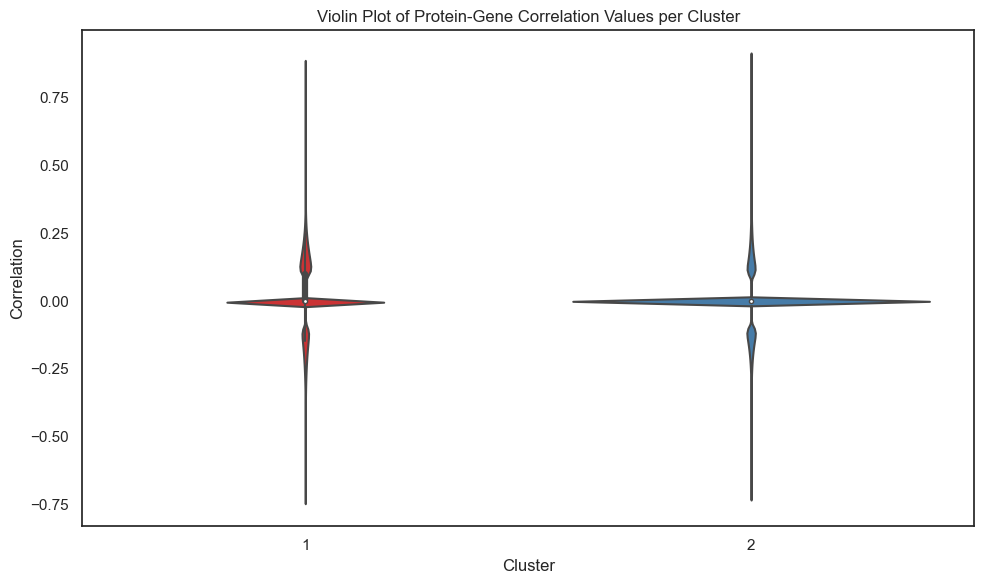

In [18]:
import scipy.cluster.hierarchy as sch


# ----- 1. Distribution Plots of Correlation Values ----- #

# (a) Violin Plot: Distribution of all protein–gene correlations per cluster.
# Add the cluster labels to the data:
# 1. Copy data and add the cluster labels
data = pearson_clean.copy()
data["Cluster"] = clusters

# 2. Name the index "Protein"
data.index.name = "Protein"

# 3. Reset the index so "Protein" becomes a column
data.reset_index(inplace=True)

# 4. Melt the DataFrame, specifying the correct 'id_vars'
data_melted = data.melt(
    id_vars=["Protein", "Cluster"],
    var_name="Gene",
    value_name="Correlation"
)

# 5. Plot
plt.figure(figsize=(10, 6))
sns.violinplot(data=data_melted, x="Cluster", y="Correlation", palette="Set1")
plt.title("Violin Plot of Protein-Gene Correlation Values per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Correlation")
plt.tight_layout()
plt.show()





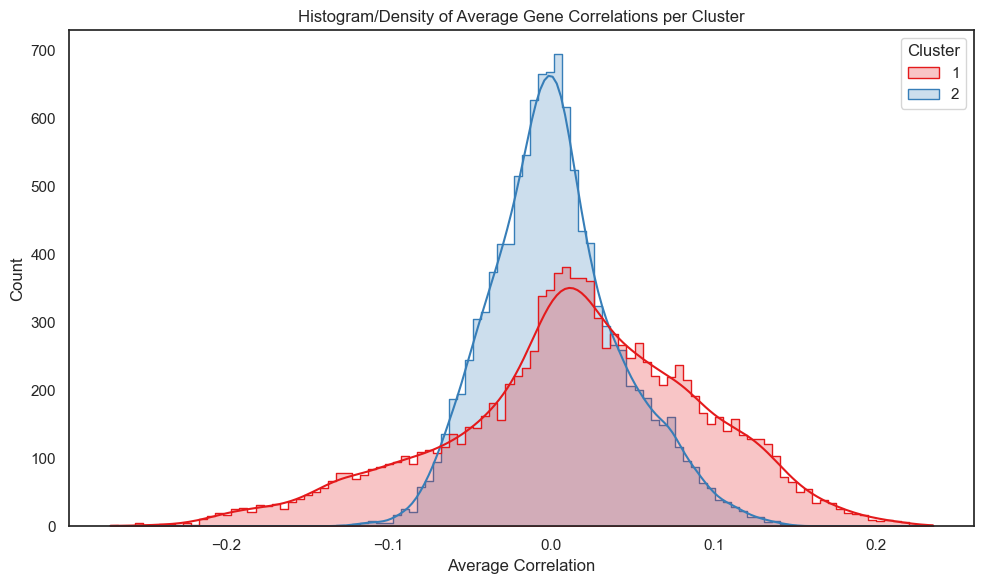

Cluster Centroids (Average Profiles):
             A1BG    A4GALT      AAAS      AACS     AADAT     AAGAB      AAK1  \
Cluster                                                                         
1        0.069820 -0.131587  0.142882 -0.012394 -0.049493 -0.015679 -0.061261   
2       -0.029863  0.052801 -0.060177  0.012151  0.053900  0.025078  0.043719   

            AAMDC      AAMP      AAR2  ...      ZUP1      ZW10    ZWILCH  \
Cluster                                ...                                 
1       -0.072473 -0.003276  0.007603  ...  0.052510  0.037200  0.020591   
2        0.037546  0.028430  0.006756  ... -0.004752 -0.001999 -0.001596   

            ZWINT      ZXDB      ZXDC    ZYG11B       ZYX     ZZEF1      ZZZ3  
Cluster                                                                        
1        0.059295  0.022432  0.076451  0.010083 -0.121768  0.071945  0.028067  
2       -0.016745  0.000403 -0.012052  0.015383  0.070614 -0.026347  0.007212  

[2 rows x 1

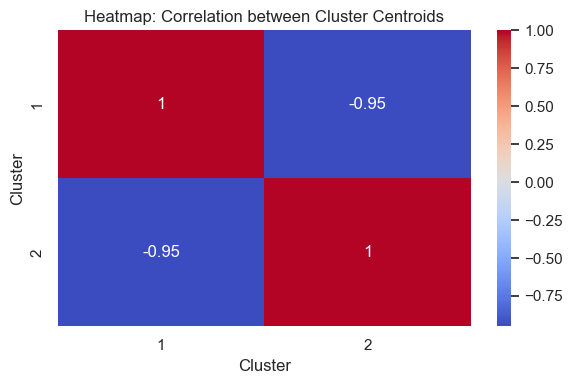


Euclidean distances between Cluster Centroids:
Cluster          1          2
Cluster                      
1         0.000000  12.673943
2        12.673943   0.000000


In [19]:

from scipy.spatial.distance import pdist, squareform

# Ensure 'Cluster' column is categorical if it's not numeric
if 'Cluster' in data.columns:
    data['Cluster'] = data['Cluster'].astype(str)  # Convert to string if needed

# (b) Histogram/Density Plot: Distribution of average gene correlations in each cluster.
# Exclude non-numeric columns before computing the mean
numeric_cols = data.select_dtypes(include=['number']).columns  # Select only numeric columns
cluster_averages = data.groupby('Cluster')[numeric_cols].mean()

# Melt the cluster averages (each row: one gene in one cluster, with its average correlation)
cluster_avg_melted = cluster_averages.reset_index().melt(id_vars='Cluster', var_name='Gene', value_name='Avg_Correlation')

# Plot the histogram/density plot
plt.figure(figsize=(10, 6))
sns.histplot(data=cluster_avg_melted, x='Avg_Correlation', hue='Cluster', palette='Set1', kde=True, element='step')
plt.title("Histogram/Density of Average Gene Correlations per Cluster")
plt.xlabel("Average Correlation")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# ----- 2. Cluster-Level “Profiles” ----- #

# Compute the centroid (average profile) for each cluster (across genes)
centroids = cluster_averages  # Already computed

print("Cluster Centroids (Average Profiles):")
print(centroids)

# (a) Compute pairwise correlation between centroids (transposing so genes are observations)
centroid_corr = centroids.T.corr()
print("\nCorrelation between Cluster Centroids:")
print(centroid_corr)

# Plot correlation heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(centroid_corr, annot=True, cmap='coolwarm')
plt.title("Heatmap: Correlation between Cluster Centroids")
plt.tight_layout()
plt.show()

# (b) Compute Euclidean distances between centroids
centroid_dist = pd.DataFrame(squareform(pdist(centroids)), index=centroids.index, columns=centroids.index)

print("\nEuclidean distances between Cluster Centroids:")
print(centroid_dist)


#### Correlation network

In [ ]:
# pip install community


  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for community: filename=community-1.0.0b1-py3-none-any.whl size=2143 sha256=50098f49c4cec00a1abce8438be39276c5c1d81156b29edf9993e26313edb7e3
  Stored in directory: c:\users\hp\appdata\local\pip\cache\wheels\b7\c9\3f\e222b011e31d3d1de1fd799caed228f770d56f66563014285d
Successfully built community


In [26]:
# pip install python-louvain


Network Density: 0.031833535493771895
community_louvain not installed; skipping modularity calculation.

Top 5 Hub Proteins (by Degree Centrality):
GNG12: 0.1504
LMNA: 0.1491
MYO1C: 0.1483
PPP1R8: 0.1463
DNAJC8: 0.1459


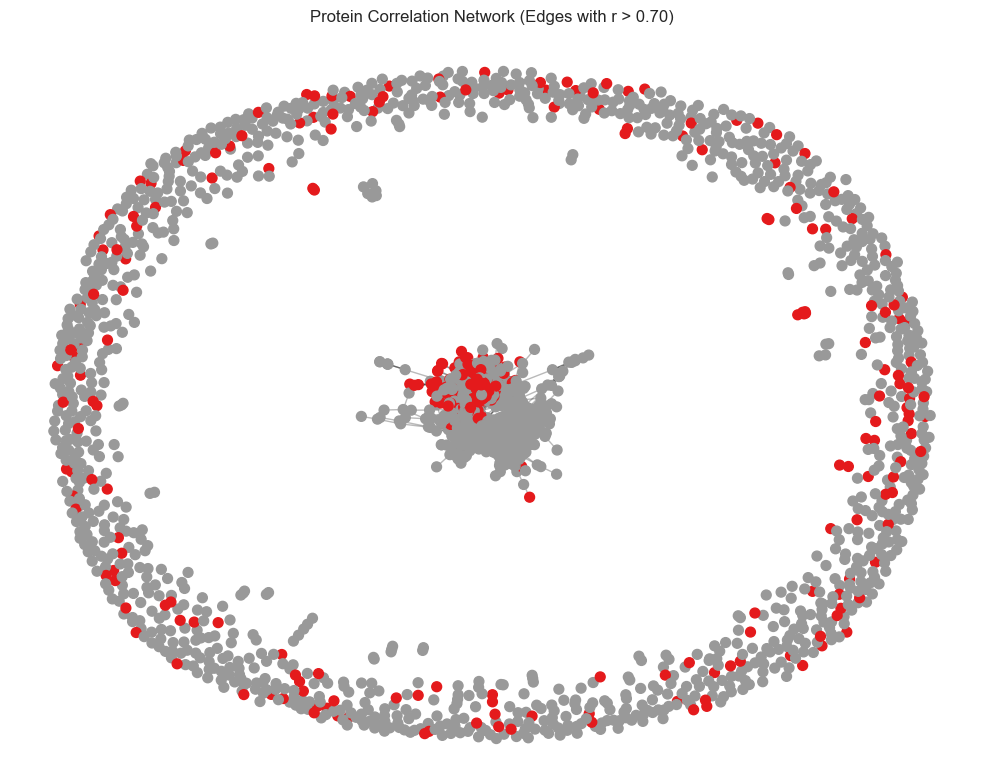

In [20]:
# ----- 3. Correlation Network Analysis ----- #

# Build a network where nodes are proteins and an edge exists if the similarity between their gene correlation profiles is high.
# Here, compute the protein–protein correlation matrix using the rows of pearson_clean.
protein_corr = pearson_clean.T.corr()  # proteins x proteins

# Set a correlation threshold for connecting nodes 
corr_threshold = 0.7

# Create an undirected graph
G = nx.Graph()

# Map each protein (row) to its cluster label
protein_cluster_mapping = dict(zip(pearson_clean.index, clusters))

# Add nodes with cluster attribute
for protein in protein_corr.index:
    G.add_node(protein, cluster=protein_cluster_mapping[protein])

# Add edges between proteins with correlation above the threshold
for i, protein_i in enumerate(protein_corr.index):
    for j, protein_j in enumerate(protein_corr.columns):
        if i < j and protein_corr.loc[protein_i, protein_j] > corr_threshold:
            G.add_edge(protein_i, protein_j, weight=protein_corr.loc[protein_i, protein_j])

# Compute network density
density = nx.density(G)
print("\nNetwork Density:", density)

# For modularity, we can use the community_louvain package (install via pip install python-louvain) 
try:
    import community as community_louvain
    partition = community_louvain.best_partition(G)
    modularity = community_louvain.modularity(partition, G)
    print("Network Modularity:", modularity)
except ImportError:
    print("community_louvain not installed; skipping modularity calculation.")

# Identify hub proteins (top 5 by degree centrality)
degree_centrality = nx.degree_centrality(G)
sorted_hubs = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)
print("\nTop 5 Hub Proteins (by Degree Centrality):")
for protein, centrality in sorted_hubs[:5]:
    print(f"{protein}: {centrality:.4f}")

# Optionally, visualize the network (this can be messy for large networks)
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G, seed=42)  # positions for all nodes
node_colors = [G.nodes[node]['cluster'] for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=50, cmap=plt.cm.Set1, node_color=node_colors)
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title("Protein Correlation Network (Edges with r > {:.2f})".format(corr_threshold))
plt.axis("off")
plt.tight_layout()
plt.show()

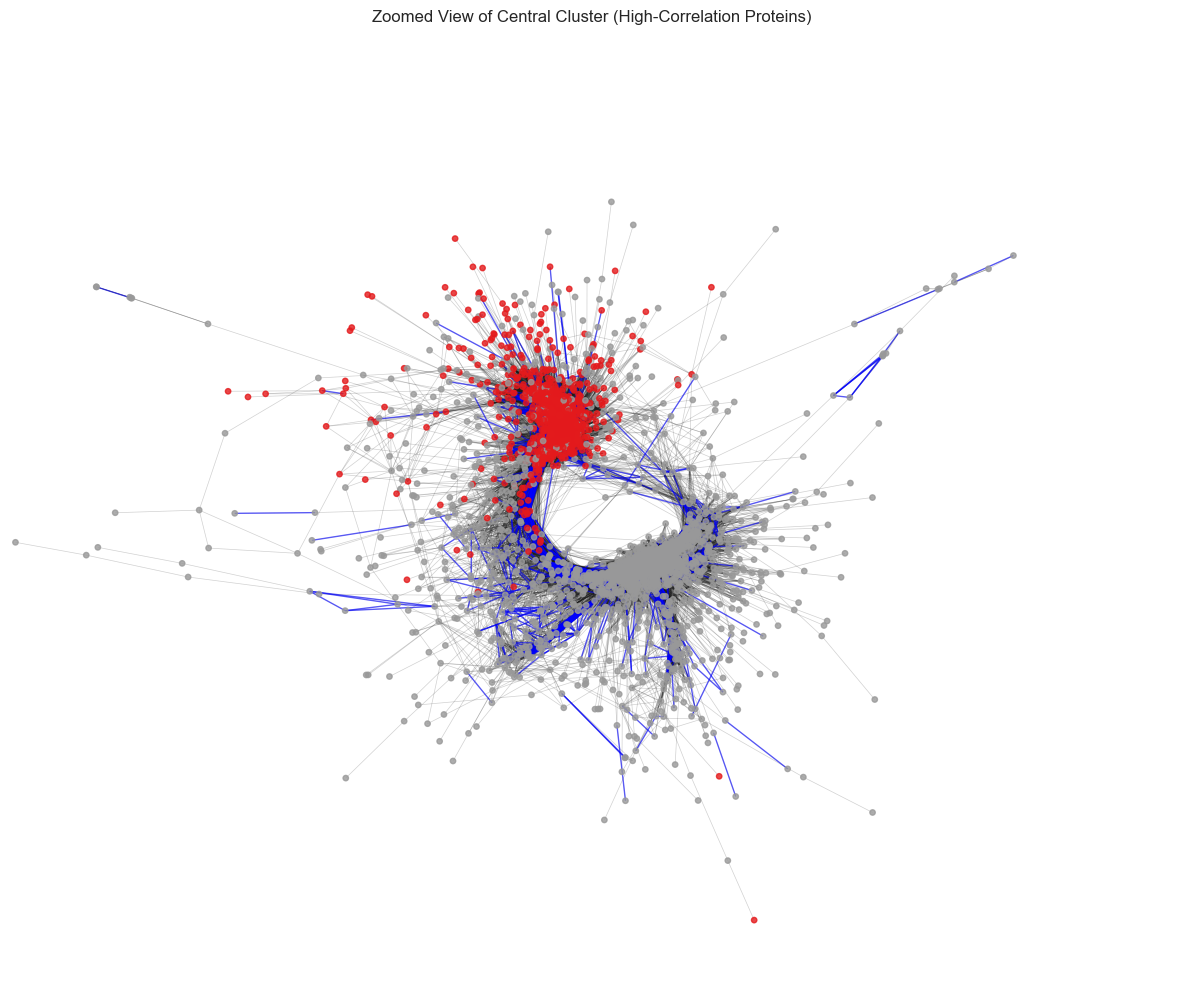

In [ ]:
# Create zoomed version of central cluster
plt.figure(figsize=(12, 10))

# Get the same layout as the original visualization for consistency
pos = nx.spring_layout(G, seed=42)  # Use same seed as original for consistency

# Get the approximate center coordinates
x_coords = [coord[0] for coord in pos.values()]
y_coords = [coord[1] for coord in pos.values()]
center_x = sum(x_coords) / len(x_coords)
center_y = sum(y_coords) / len(y_coords)

# Define radius for central region
radius = 0.3  # Adjust this value to control zoom level

# Identify nodes in the central region
central_nodes = [node for node in G.nodes() if 
                ((pos[node][0] - center_x)**2 + (pos[node][1] - center_y)**2) < radius**2]

# Draw edges with increased transparency for better visibility
central_edge_list = [(u, v) for u, v in G.edges() if u in central_nodes and v in central_nodes]
central_G = nx.Graph()
central_G.add_edges_from(central_edge_list)
nx.draw_networkx_edges(central_G, pos, alpha=0.2, width=0.5)

# Draw high correlation edges more prominently
high_corr_edges = [(u, v) for u, v, d in G.edges(data=True) 
                  if d['weight'] > 0.8 and u in central_nodes and v in central_nodes]
high_corr_G = nx.Graph()
high_corr_G.add_edges_from(high_corr_edges)
nx.draw_networkx_edges(high_corr_G, pos, alpha=0.6, width=1.0, edge_color='blue')

# Draw nodes for central region
central_nodes_colors = [G.nodes[node]['cluster'] for node in central_nodes]
nx.draw_networkx_nodes(G, pos, nodelist=central_nodes, node_size=15, 
                      alpha=0.8, cmap=plt.cm.Set1, node_color=central_nodes_colors)

# Add labels for hub proteins in central region (top 10)
top_hubs = [protein for protein, _ in sorted_hubs[:10]]
#central_hub_labels = {node: node for node in top_hubs if node in central_nodes}
#nx.draw_networkx_labels(G, pos, labels=central_hub_labels, font_size=10, font_color='black', font_weight='bold')

# Set plot limits for zoom effect
plt.xlim(center_x - radius, center_x + radius)
plt.ylim(center_y - radius, center_y + radius)4

plt.title("Zoomed View of Central Cluster (High-Correlation Proteins)")
plt.axis("off")
plt.tight_layout()
plt.savefig("zoomed_central_cluster.png", dpi=300)
plt.show()

#### Save Network

In [28]:

# 1. Save the cluster assignments for each protein
cluster_df = pd.DataFrame({
    'Protein': list(protein_cluster_mapping.keys()),
    'Cluster': list(protein_cluster_mapping.values())
})
cluster_df.to_csv('protein_clusters.csv', index=False)

# 2. Save community detection results (Louvain algorithm)
if 'partition' in locals():
    community_df = pd.DataFrame({
        'Protein': list(partition.keys()),
        'Community': list(partition.values())
    })
    community_df.to_csv('protein_communities.csv', index=False)

# 3. Save network properties of each protein
# Degree centrality
degree_df = pd.DataFrame({
    'Protein': list(degree_centrality.keys()),
    'DegreeCentrality': list(degree_centrality.values())
})

# You could also calculate other centrality measures
betweenness_centrality = nx.betweenness_centrality(G)
closeness_centrality = nx.closeness_centrality(G)

# Add these measures to the dataframe
degree_df['BetweennessCentrality'] = [betweenness_centrality.get(p, 0) for p in degree_df['Protein']]
degree_df['ClosenessCentrality'] = [closeness_centrality.get(p, 0) for p in degree_df['Protein']]

# Add cluster information
degree_df['Cluster'] = [protein_cluster_mapping.get(p, -1) for p in degree_df['Protein']]

# Save to CSV
degree_df.to_csv('protein_network_properties.csv', index=False)

# 4. Save the network edges to a file
edges_list = list(G.edges(data=True))
edge_df = pd.DataFrame([
    {'Protein1': p1, 'Protein2': p2, 'Weight': data.get('weight', 0)} 
    for p1, p2, data in edges_list
])
edge_df.to_csv('protein_network_edges.csv', index=False)

# 5. For more advanced analysis, you could save as GraphML format
# which preserves the full network structure for loading into tools like Cytoscape
nx.write_graphml(G, 'protein_correlation_network.graphml')

print("All network analysis results saved to CSV files")

All network analysis results saved to CSV files


# Spearman

In [34]:
spearman = load('data/full_spearman.joblib')
spearman

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A4GALT,AAAS,AACS,AACSP1,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.259988,0.233929,-0.116902,0.230195,0.000000,-0.142924,0.000000,0.000000,0.000000,0.0,...,0.139395,0.000000,0.000000,0.000000,0.000000,0.000000,0.225174,0.170703,0.000000,0.123180
AAAS,0.000000,0.000000,0.000000,0.000000,0.121819,0.111012,0.000000,0.000000,-0.166863,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.109546,0.000000,0.000000,-0.127864,0.114503
AACS,0.000000,0.000000,0.000000,0.000000,0.000000,-0.147828,0.000000,0.000000,0.446383,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.127329,0.103151,0.000000,0.000000,0.000000,-0.157370,-0.153830,0.197541,0.120025,0.0,...,0.218814,0.000000,0.117859,0.117173,0.000000,0.000000,0.000000,0.000000,0.209716,0.000000
AAK1,0.182794,0.179434,0.000000,0.000000,0.000000,-0.114290,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.144951,0.000000,0.000000,0.000000,0.239220,0.291094,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RUVBL2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.106743,-0.106265,0.0,...,0.000000,0.000000,0.000000,0.000000,0.150135,0.000000,0.000000,0.000000,0.000000,0.000000
RYBP,0.106975,0.000000,0.000000,0.000000,0.000000,0.000000,-0.208265,0.189727,0.000000,0.0,...,0.000000,0.183956,0.000000,0.000000,0.218500,0.000000,0.000000,-0.125549,0.156089,0.000000
S100A10,-0.295469,-0.275389,0.129749,-0.177183,0.000000,0.120204,0.359290,-0.332902,0.000000,0.0,...,0.000000,-0.147222,0.000000,0.000000,-0.194365,0.000000,0.000000,0.235213,-0.181334,0.000000


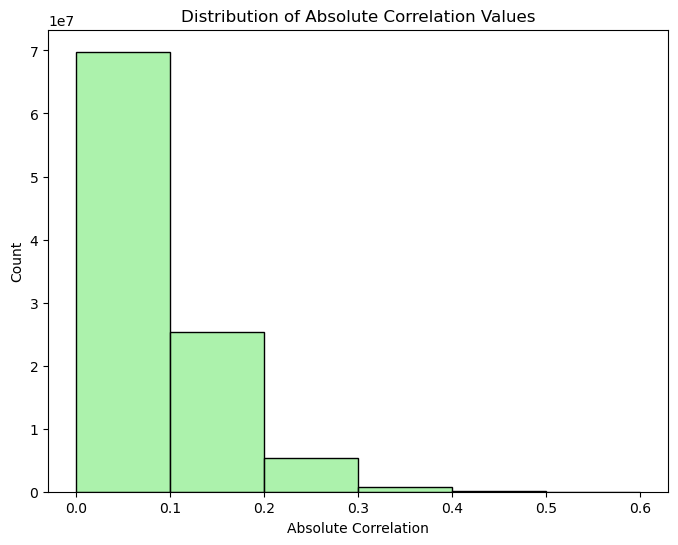

In [35]:
abs_values = spearman.abs().values.flatten()

#bins (0–0.1, 0.1–0.2, 0.2–0.3, ..., 0.9)
bins = np.arange(0, 0.7, 0.1)

plt.figure(figsize=(8, 6))
sns.histplot(abs_values, bins=bins, kde=False, color='lightgreen', edgecolor='black')
plt.xlabel('Absolute Correlation')
plt.ylabel('Count')
plt.title('Distribution of Absolute Correlation Values')
plt.xticks(bins)  # Ensure the x-axis shows the bin edges
plt.show()


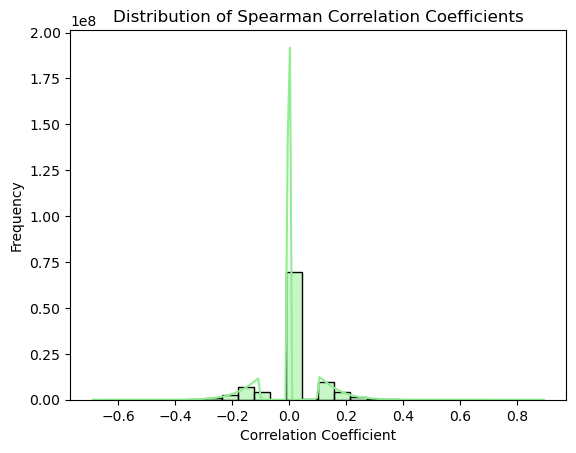

In [50]:
data = spearman.values.flatten()

# Create a histogram with a kernel density estimate (KDE) in skyblue
sns.histplot(data, color='lightgreen', kde=True)

# Optional customizations
plt.title("Distribution of Spearman Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")

# Display the plot
plt.show()

filter out zeros

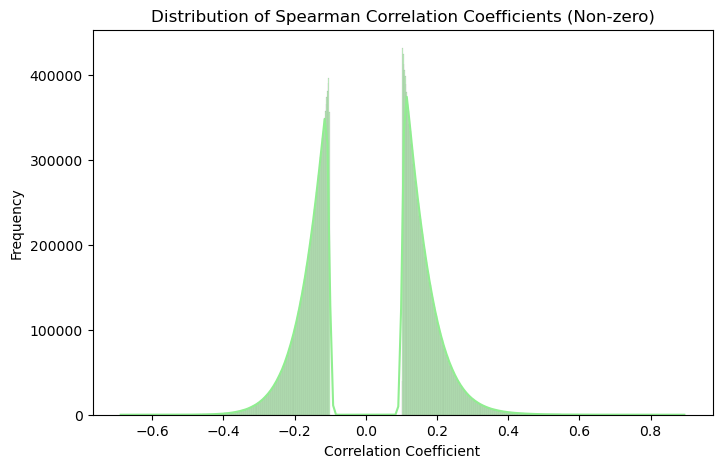

In [52]:
# Filter out exact zeros or near-zeros
non_zero_data = data[np.isclose(data, 0, atol=1e-10) == False]

plt.figure(figsize=(8, 5))
sns.histplot(non_zero_data, color='lightgreen', kde=True)
plt.title("Distribution of Spearman Correlation Coefficients (Non-zero)")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")
plt.show()

### Plot protein - # correlated genes

how many zeros


In [36]:
zero_counts = (spearman == 0).sum(axis=1)

# Compute the number of genes correlated above thresholds
thresholds = [0.1, 0.2, 0.3]
thresh_counts = {t: (spearman.abs() > t).sum(axis=1) for t in thresholds}

In [37]:
print_summary()

          Zero Correlations  Correlated > 0.1  Correlated > 0.2  \
proteins                                                          
A2M                   15713             10282              2847   
AAAS                  21163              4832               240   
AACS                  22157              3838               121   
AAGAB                 17925              8070               872   
AAK1                  15616             10379              2799   
...                     ...               ...               ...   
RUVBL2                21625              4370               155   
RYBP                  15113             10882              2730   
S100A10               11266             14729              6753   
S100A11               14069             11926              3535   
S100A13               16522              9473              1810   

          Correlated > 0.3  
proteins                    
A2M                    372  
AAAS                     0  
AACS        

The following histogram displays how many genes per protein have correlations above 0.1 (absolute value). It helps to understand whether most genes have weak or strong correlations with each protein.

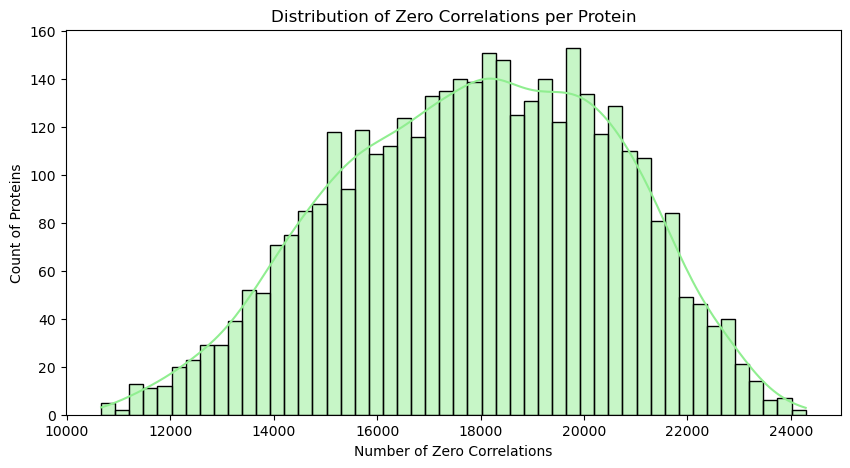

In [38]:
# Cell 1: Plot histogram of zero counts
plt.figure(figsize=(10, 5))
sns.histplot(zero_counts, bins=50, color ="lightgreen", kde=True)
plt.xlabel("Number of Zero Correlations")
plt.ylabel("Count of Proteins")
plt.title("Distribution of Zero Correlations per Protein")
plt.show()

## Above 0.1 absolute correlation

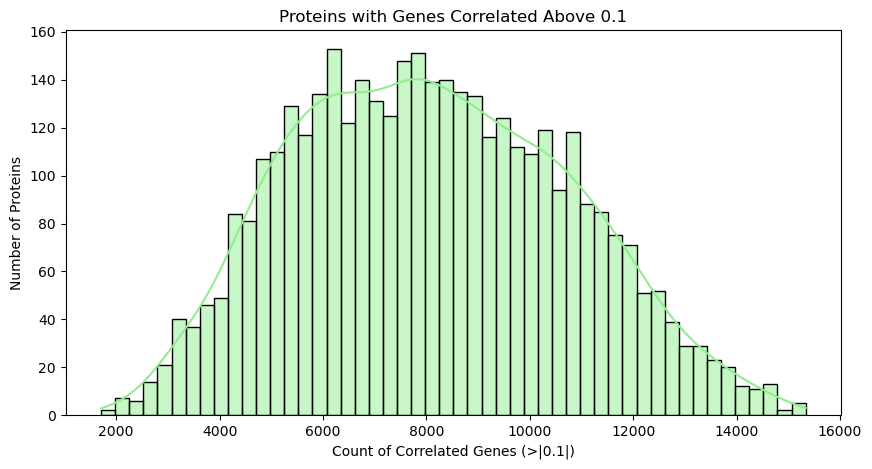

In [39]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.1], bins=50, color ="lightgreen", kde=True)
plt.xlabel("Count of Correlated Genes (>|0.1|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.1")
plt.show()

## Above 0.2 absolute correlation

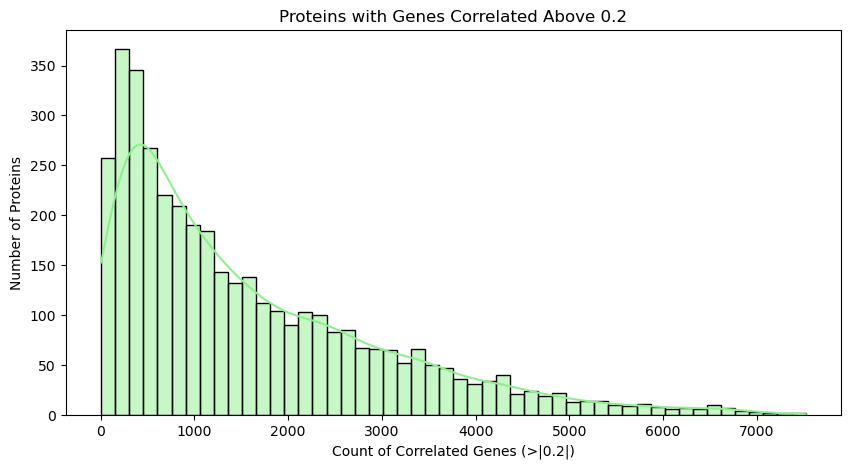

In [40]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.2], bins=50,color ="lightgreen",  kde=True)
plt.xlabel("Count of Correlated Genes (>|0.2|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.2")
plt.show()

## Above 0.3 absolute correlation

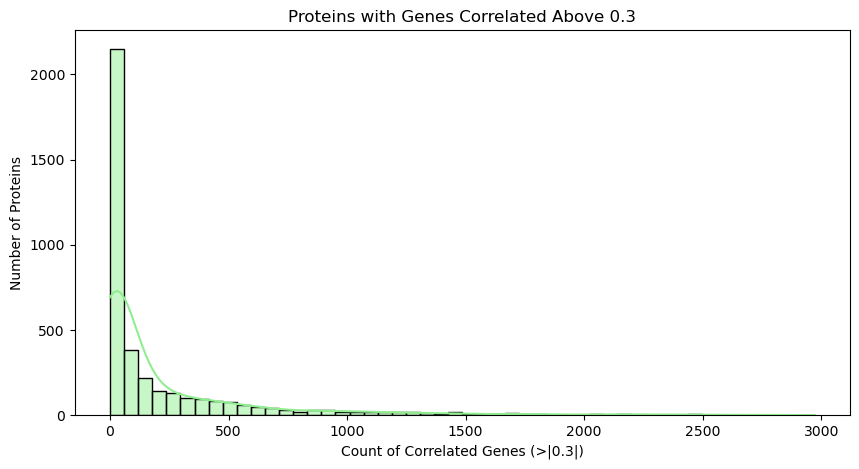

In [41]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.3], bins=50,color ="lightgreen",  kde=True)
plt.xlabel("Count of Correlated Genes (>|0.3|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.3")
plt.show()